In [1]:
import pandas as pd
import numpy as np

In [2]:
# SFMS
slope = 0.86
intercept=-8.5
def del_SFMS(Mstar, SFR):
    SFMS = slope * Mstar + intercept
    del_SFMS = SFR - SFMS
    return del_SFMS

def is_quenched(del_SFMS):
    if del_SFMS < -0.5:
        return True
    else:
        return False

In [3]:
high_mass_satellite_df = pd.read_parquet ('../../data/high_mass_satellite_df_annuli_revised.parquet')
print('length of high- mass satellites df:', len(high_mass_satellite_df))

# --- remove quenched galaxies using del_SFMS and is_quenched ---
# del_SFMS takes (log Mstar, log SFR); 's_mass' is in 1e10 Msun and 'global_SFRs' in Msun/yr, so convert to log10 first
high_mass_satellite_df['del_SFMS'] = del_SFMS(np.log10(high_mass_satellite_df['s_mass'] * 1e10), np.log10(high_mass_satellite_df['global_SFRs']))

# is_quenched expects the del_SFMS value
quenched_mask = high_mass_satellite_df['del_SFMS'].apply(is_quenched)
removed = quenched_mask.sum()
high_mass_satellite_df = high_mass_satellite_df[~quenched_mask].reset_index(drop=True)
print(f"Removed {removed} quenched rows; remaining {len(high_mass_satellite_df)} rows.")

# drop helper column (global del_SFMS, only used for the star-forming selection)
high_mass_satellite_df = high_mass_satellite_df.drop(columns=['del_SFMS'])
print(f"filtered dataframe has {len(high_mass_satellite_df)} rows.")

# --- resolved deviation from the rSFMS (log Sigma_SFR vs log Sigma_*, from Galaxy Partitioning - Annuli Revised) ---
rsfms_slope = 0.793
rsfms_intercept = -7.57
def del_sig_SFR(log_sigma_star, log_sigma_SFR):
    return log_sigma_SFR - (rsfms_slope * log_sigma_star + rsfms_intercept)

# avg_s_mass / avg_SFR are the annulus-averaged log surface densities
high_mass_satellite_df['del_sig_SFR'] = del_sig_SFR(high_mass_satellite_df['avg_s_mass'], high_mass_satellite_df['avg_SFR'])


length of high- mass satellites df: 8675
Removed 6460 quenched rows; remaining 2215 rows.
filtered dataframe has 2215 rows.


In [4]:
high_mass_satellite_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,...,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr,del_sig_SFR
0,3.0,0.047010,9.952458,-2.017939,6.346932,0,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-2.340238
1,3.0,0.141030,9.672738,-2.325411,6.341232,1,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-2.425891
2,3.0,0.235050,9.296635,-2.709024,6.330259,1,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-2.511256
3,3.0,0.329069,8.998160,-3.019758,6.319237,1,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-2.585299
4,3.0,0.423089,8.809211,-3.144438,6.331594,1,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-2.560143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2210,462987.0,0.173652,9.171778,-0.202319,8.651024,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,0.094461
2211,462987.0,0.520957,8.854676,-0.765807,8.399230,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,-0.217565
2212,462987.0,0.868261,8.582487,-1.080499,8.100421,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,-0.316411
2213,462987.0,1.215566,8.400651,-1.433384,7.964696,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,-0.525101


In [5]:
# # calculating star forming efficiency (SFE) and gas fraction 
# low_mass_satellite_df['SFE'] = 10**(low_mass_satellite_df['del_sig_SFR'] - low_mass_satellite_df['avg_gas_mass'])
# low_mass_satellite_df['f_gas'] = 10**(low_mass_satellite_df['avg_gas_mass'] - low_mass_satellite_df['avg_s_mass'])

In [6]:
# # remove the rows where the sfr_indicator is 0.0 -> implies artificially imposed minimum
# low_mass_satellite_df = low_mass_satellite_df[low_mass_satellite_df['sfr_indicator'] != 0.0]
# low_mass_satellite_df

In [7]:
# star forming quenching vector value = 0
high_mass_satellite_df = high_mass_satellite_df[high_mass_satellite_df['quenching_vector'] != 1]
high_mass_satellite_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,...,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr,del_sig_SFR
0,3.0,0.047010,9.952458,-2.017939,6.346932,0,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-2.340238
10,3.0,0.987208,8.100429,-2.680269,7.045229,0,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-1.533908
11,3.0,1.081228,8.032700,-2.030120,7.293589,0,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-0.830051
12,3.0,1.175248,7.974018,-2.021196,7.425975,0,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-0.774592
13,3.0,1.269268,7.942819,-1.817953,7.475906,0,0.0,17.155148,0.034418,1,...,4.710709,1.070481e+07,1.388802e-316,38878.035156,94.438007,0.206207,0.122587,1.070481e+07,0,-0.546609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2210,462987.0,0.173652,9.171778,-0.202319,8.651024,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,0.094461
2211,462987.0,0.520957,8.854676,-0.765807,8.399230,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,-0.217565
2212,462987.0,0.868261,8.582487,-1.080499,8.100421,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,-0.316411
2213,462987.0,1.215566,8.400651,-1.433384,7.964696,0,0.0,2.001361,0.003254,1,...,2.233273,7.552357e+01,0.000000e+00,129.809052,0.046284,-1.015946,0.104524,7.552357e+01,1113,-0.525101


In [8]:
high_mass_satellite_df.shape

(2014, 21)

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import RobustScaler

# 'BHMass', 'BHCum_QM', 'Mhalo', 'overdens', and 'bulge' are the features wer are testing
high_mass_satellite_df = high_mass_satellite_df.drop(columns=["class", "BH_cumQM", "BH_cumRM", "global_SFRs", "gas_mass","avg_gas_mass", "quenching_vector", "Bfld", "veldisp", "BH_AGN", "bulge", "avg_SFR"])  # avg_SFR dropped as a feature (target is now del_sig_SFR)

<Axes: >

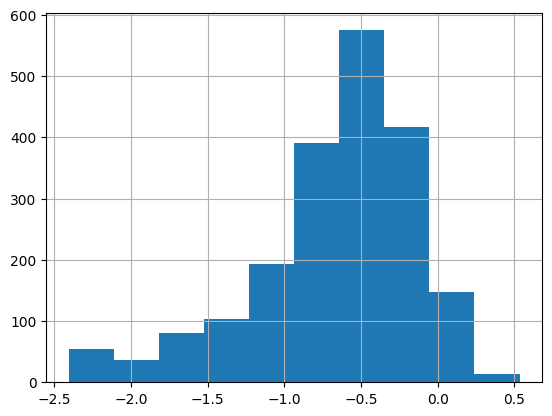

In [10]:
high_mass_satellite_df['del_sig_SFR'].hist()

In [11]:
# this indicates that there are more instances of the delta rate on the left

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

feature_importances_list = []
feature_names = None
test_mses = []
train_mses = []


for seed in range(10):
    # split halos (GrNr) into 50% training and 50% testing, so galaxies from the same halo never span train and test
    unique_halos = np.unique(high_mass_satellite_df['GrNr'])
    train_galaxies, test_galaxies = train_test_split(unique_halos, test_size=0.5, random_state=seed)

    # assign galaxies based on halo split
    train_data = high_mass_satellite_df[high_mass_satellite_df['GrNr'].isin(train_galaxies)]
    test_data = high_mass_satellite_df[high_mass_satellite_df['GrNr'].isin(test_galaxies)]

    X_train, y_train = train_data.drop(columns=['del_sig_SFR', 'subID', 'GrNr']), train_data['del_sig_SFR']
    X_test, y_test = test_data.drop(columns=['del_sig_SFR', 'subID', 'GrNr']), test_data['del_sig_SFR']
    
    
    if feature_names is None:
        feature_names = X_train.columns.tolist()

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    groups_train = train_data['GrNr']
    cv = GroupKFold(n_splits=5)

    # XGBoost Regressor
    xgb_regressor = XGBRegressor(random_state=seed, n_jobs=-1)

    param_grid = {
    'n_estimators': [100,150,200,250],
    'max_depth': [1],
    'learning_rate': [0.01],
    'subsample': [0.5,0.6, 0.7],
    'colsample_bytree': [1.0],
    'min_child_weight': [20, 25, 30],
    'alpha': [8, 12, 15],
    'lambda': [15, 20, 25]#, 30, 35]
    }
    """
    param_grid = {
    'n_estimators': [600],
    'max_depth': [2],
    'learning_rate': [0.006],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [1.0],
    'min_child_weight': [30, 40, 50],
    'alpha': [3, 4, 5],
    'lambda': [2, 3, 4],
    }
    """

    grid_search = GridSearchCV(
    estimator=xgb_regressor, 
    param_grid=param_grid, 
    cv=cv, 
    scoring='neg_mean_squared_error',
    n_jobs=-1, 
    verbose=2
    )

    grid_search.fit(X_train_scaled, y_train, groups=groups_train)

    best_xg_regressor = grid_search.best_estimator_
    print(f"Best parameters for seed {seed+1}: {grid_search.best_params_}")

    best_xg_regressor.fit(X_train_scaled, y_train)
    
    y_train_pred = best_xg_regressor.predict(X_train_scaled)
    y_test_pred = best_xg_regressor.predict(X_test_scaled)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    print(f"Run {seed+1}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}, Gap= {test_mse - train_mse:.4f}")
    
    train_mses.append(train_mse)
    test_mses.append(test_mse)
    
    feature_importances_list.append(best_xg_regressor.feature_importances_)
#     print(random_search.best_params_)
    #print(f"Run {seed+1}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}")

print("\nAverage MSE over 10 runs:")
print(f"Train MSE: Mean = {np.mean(train_mses):.4f}, Std = {np.std(train_mses):.4f}")
print(f"Test MSE:  Mean = {np.mean(test_mses):.4f}, Std = {np.std(test_mses):.4f}")


Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Best parameters for seed 1: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 200, 'subsample': 0.7}
Run 1: Train MSE = 0.2655, Test MSE = 0.2816, Gap= 0.0161
Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Best parameters for seed 2: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 25, 'n_estimators': 250, 'subsample': 0.7}
Run 2: Train MSE = 0.2663, Test MSE = 0.2727, Gap= 0.0064
Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Best parameters for seed 3: {'alpha': 8, 'colsample_bytree': 1.0, 'lambda': 15, 'learning_rate': 0.01, 'max_depth': 1, 'min_child_weight': 20, 'n_estimators': 250, 'subsample': 0.7}
Run 3: Train MSE = 0.2678, Test MSE = 0.2715, Gap= 0.0037
Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Best parameters for seed


=== Average Feature Importances ===
      Feature  Mean Importance   Std Dev
1  avg_s_mass         0.212924  0.042608
0   bin_radii         0.211604  0.033926
3      BHMass         0.185281  0.025573
2      s_mass         0.147854  0.071963
5    overdens         0.136809  0.062409
4       Mhalo         0.105528  0.065246


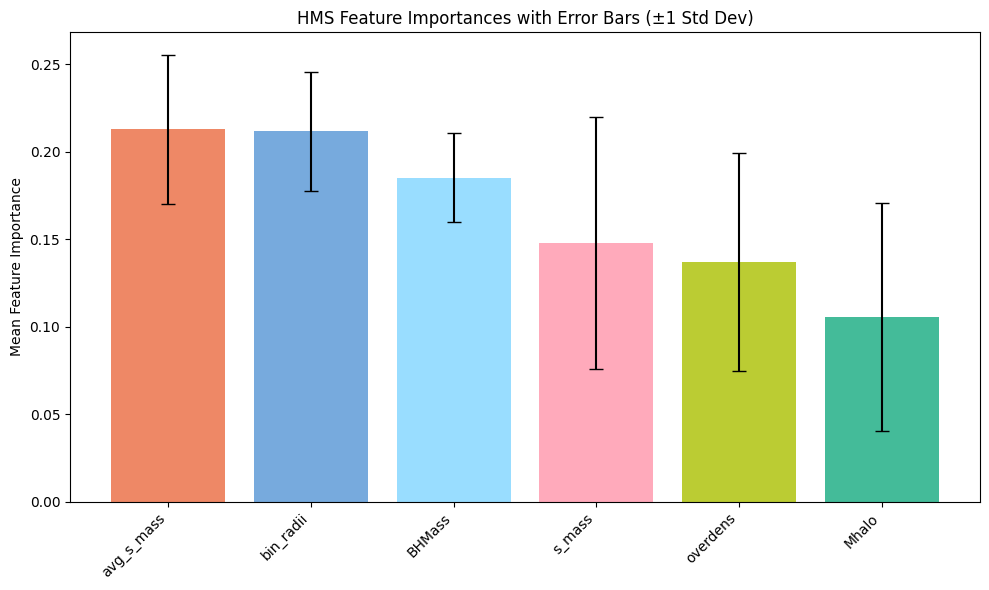

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
feature_colors = {
    'bin_radii': '#77AADD',
    'avg_s_mass': '#EE8866',
    's_mass': '#FFAABB',
    'BHMass': '#99DDFF',
    'Mhalo': '#44BB99',
    'overdens': '#BBCC33',
    'bulge': '#AAAA00',
    'BH_AGN': '#DDDDDD',
}

# importances + stds across 10 runs
importances_array = np.array(feature_importances_list)
importance_means = np.mean(importances_array, axis=0)
importance_stds = np.std(importances_array, axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Importance': importance_means,
    'Std Dev': importance_stds
}).sort_values(by='Mean Importance', ascending=False)

print("\n=== Average Feature Importances ===")
print(importance_df)

colors = [feature_colors[feat] for feat in importance_df['Feature']]
# Plot
plt.figure(figsize=(10, 6))
plt.bar(importance_df['Feature'], importance_df['Mean Importance'], yerr=importance_df['Std Dev'], capsize=5, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Mean Feature Importance")
plt.title("HMS Feature Importances with Error Bars (±1 Std Dev)")
plt.tight_layout()
plt.show()

In [14]:
high_mass_satellite_df.corr()

,subID,bin_radii,avg_s_mass,s_mass,BHMass,Mhalo,overdens,GrNr,del_sig_SFR
subID,1.000000,-0.029819,0.002871,-0.364613,-0.371436,-0.826804,-0.288460,0.846843,0.051090
bin_radii,-0.029819,1.000000,-0.825092,0.012287,0.015675,0.034534,-0.003268,-0.021863,0.181510
avg_s_mass,0.002871,-0.825092,1.000000,0.101951,0.107752,0.015069,0.080725,0.037481,-0.157174
s_mass,-0.364613,0.012287,0.101951,1.000000,0.992970,0.335198,0.633664,-0.234770,-0.089126
BHMass,-0.371436,0.015675,0.107752,0.992970,1.000000,0.348203,0.604252,-0.237820,-0.095048
Mhalo,-0.826804,0.034534,0.015069,0.335198,0.348203,1.000000,0.225916,-0.487349,-0.042438
overdens,-0.288460,-0.003268,0.080725,0.633664,0.604252,0.225916,1.000000,-0.187172,-0.050024
GrNr,0.846843,-0.021863,0.037481,-0.234770,-0.237820,-0.487349,-0.187172,1.000000,0.028921
del_sig_SFR,0.051090,0.181510,-0.157174,-0.089126,-0.095048,-0.042438,-0.050024,0.028921,1.000000


In [15]:
import os
# Define your directory and file name
directory = 'xg_regression_outputs'
filename = 'hms_xg_reg_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
importance_df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

DataFrame saved to xg_regression_outputs\hms_xg_reg_halosplit.csv


In [16]:
train_mean = round(np.mean(train_mses), 2)
test_mean = round(np.mean(test_mses), 2)

df = pd.DataFrame({
    'Train MSE': [train_mean],
    'Test MSE': [test_mean]
})

print(df)
import os
# Define your directory and file name
directory = 'xg_regression_outputs'
filename = 'hms_xg_reg_mse_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

   Train MSE  Test MSE
0       0.27      0.27
DataFrame saved to xg_regression_outputs\hms_xg_reg_mse_halosplit.csv
